# 📊 Gold Spot
Notebook 01: Preprocessing

## Preliminaries

In [1]:
import pandas as pd
from src.extract import fetch_fred, fetch_prices
from src.preprocessing_functions import *
from src.config import clean_data_file

### Extract macro data

In [2]:
df_macro = fetch_fred()
df_macro.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 4379 entries, 2010-01-01 to 2026-10-14
Freq: B
Data columns (total 5 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   real_yield_10y           4197 non-null   float64
 1   breakeven_inflation_10y  4198 non-null   float64
 2   dxy_broad_goods          4177 non-null   float64
 3   treasury_10y_nominal     4197 non-null   float64
 4   vix_index                4254 non-null   float64
dtypes: float64(5)
memory usage: 205.3 KB


In [3]:
# Mostrar missings iniciales
show_missings(df_macro)

dxy_broad_goods            0.046129
real_yield_10y             0.041562
treasury_10y_nominal       0.041562
breakeven_inflation_10y    0.041334
vix_index                  0.028545
dtype: float64

In [4]:
# Missings aplicando forward fill
show_missings(df_macro.ffill())

real_yield_10y             0.000228
breakeven_inflation_10y    0.000228
dxy_broad_goods            0.000228
treasury_10y_nominal       0.000228
vix_index                  0.000228
dtype: float64

In [5]:
# Se aplica el forward fill y eliminan missings iniciales
df_macro = df_macro.ffill().dropna()

In [6]:
# Se aplica retardo de 1 dia para evitar Lookahead Bias (horario de publicación luego del cierre diario)
macro_cols = df_macro.columns.to_list()
df_macro = calculate_lag(df_macro,macro_cols)
show_missings(df_macro)

real_yield_10y_lag1             0.000228
breakeven_inflation_10y_lag1    0.000228
dxy_broad_goods_lag1            0.000228
treasury_10y_nominal_lag1       0.000228
vix_index_lag1                  0.000228
dtype: float64

In [7]:
# Se eliminan missings luego de aplicar el lag
df_macro = df_macro.dropna()

In [8]:
df_macro.tail()

,real_yield_10y_lag1,breakeven_inflation_10y_lag1,dxy_broad_goods_lag1,treasury_10y_nominal_lag1,vix_index_lag1
date,,,,,
2026-10-08,2.92,2.36,121.2558,5.28,15.08
2026-10-09,2.87,2.35,121.4469,5.22,15.41
2026-10-12,2.91,2.33,121.6023,5.24,14.84
2026-10-13,2.91,2.33,121.6023,5.24,15.21
2026-10-14,2.88,2.33,121.6023,5.21,15.27


### Extract prices

In [9]:
df_prices = fetch_prices()
df_prices.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 876 entries, 2010-01-01 to 2026-10-09
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   gold    876 non-null    float64
 1   oil     876 non-null    float64
 2   spy     876 non-null    float64
dtypes: float64(3)
memory usage: 27.4 KB


In [10]:
df_prices.tail()

Ticker,gold,oil,spy
date,,,
2026-09-11,4399.700195,101.910004,762.599976
2026-09-18,4298.000000,94.610001,767.179993
2026-09-25,4202.299805,92.870003,763.989990
2026-10-02,4157.000000,91.489998,773.929993
2026-10-09,4176.000000,96.610001,769.750000


In [11]:
# Se convierten las series de precios absolutos en retornos porcentuales
price_cols = df_prices.columns.to_list()
df_returns = calculate_return(df_prices, price_cols)
df_returns.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 876 entries, 2010-01-01 to 2026-10-09
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   gold_return  875 non-null    float64
 1   oil_return   875 non-null    float64
 2   spy_return   875 non-null    float64
dtypes: float64(3)
memory usage: 27.4 KB


In [12]:
# Se eliminan missings luego de calcular los retornos
df_returns = df_returns.dropna()

### Merge datasets

In [13]:
df_merged = df_macro.merge(df_returns, how='right', on= 'date')
df_merged.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 875 entries, 2010-01-08 to 2026-10-09
Data columns (total 8 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   real_yield_10y_lag1           875 non-null    float64
 1   breakeven_inflation_10y_lag1  875 non-null    float64
 2   dxy_broad_goods_lag1          875 non-null    float64
 3   treasury_10y_nominal_lag1     875 non-null    float64
 4   vix_index_lag1                875 non-null    float64
 5   gold_return                   875 non-null    float64
 6   oil_return                    875 non-null    float64
 7   spy_return                    875 non-null    float64
dtypes: float64(8)
memory usage: 61.5 KB


In [14]:
# Crear variable target: gold_return en t+1
df_merged["target_gold_t1"] = df_merged["gold_return"].shift(-1)
df_merged.tail()

,real_yield_10y_lag1,breakeven_inflation_10y_lag1,dxy_broad_goods_lag1,treasury_10y_nominal_lag1,vix_index_lag1,gold_return,oil_return,spy_return,target_gold_t1
date,,,,,,,,,
2026-09-11,2.55,2.40,118.0787,4.95,17.84,-0.001724,-0.005562,0.006294,-0.023115
2026-09-18,2.61,2.33,119.3489,4.94,15.44,-0.023115,-0.071632,0.006006,-0.022266
2026-09-25,2.85,2.33,120.5521,5.18,15.67,-0.022266,-0.018391,-0.004158,-0.010780
2026-10-02,2.88,2.36,121.7882,5.24,16.39,-0.010780,-0.014860,0.013011,0.004571
2026-10-09,2.87,2.35,121.4469,5.22,15.41,0.004571,0.055962,-0.005401,NaN


## EDA

In [15]:
df_merged.describe()

,real_yield_10y_lag1,breakeven_inflation_10y_lag1,dxy_broad_goods_lag1,treasury_10y_nominal_lag1,vix_index_lag1,gold_return,oil_return,spy_return,target_gold_t1
count,875.000000,875.000000,875.000000,875.000000,875.000000,875.000000,875.000000,875.000000,874.000000
mean,0.616537,2.082366,109.322423,2.698903,18.394434,0.001761,0.001513,0.002418,0.001754
std,0.928764,0.339949,11.993083,1.057294,6.796225,0.023211,0.051611,0.021524,0.023223
min,-1.150000,0.500000,85.824500,0.550000,9.190000,-0.110145,-0.313726,-0.179693,-0.110145
25%,0.070000,1.845000,94.531350,1.900000,14.000000,-0.012157,-0.025833,-0.008752,-0.012167
50%,0.530000,2.170000,113.269100,2.530000,16.630000,0.003066,0.001405,0.004003,0.003043
75%,1.285000,2.330000,119.171450,3.555000,21.030000,0.015597,0.028532,0.014363,0.015619
max,2.880000,3.020000,129.459800,5.240000,75.470000,0.115988,0.250000,0.104714,0.115988


In [16]:
show_asymmetry(df_merged)

vix_index_lag1                  2.554621
treasury_10y_nominal_lag1       0.259717
oil_return                      0.112570
real_yield_10y_lag1             0.107836
target_gold_t1                 -0.106327
gold_return                    -0.107327
dxy_broad_goods_lag1           -0.515438
breakeven_inflation_10y_lag1   -0.669990
spy_return                     -1.059639


Cont


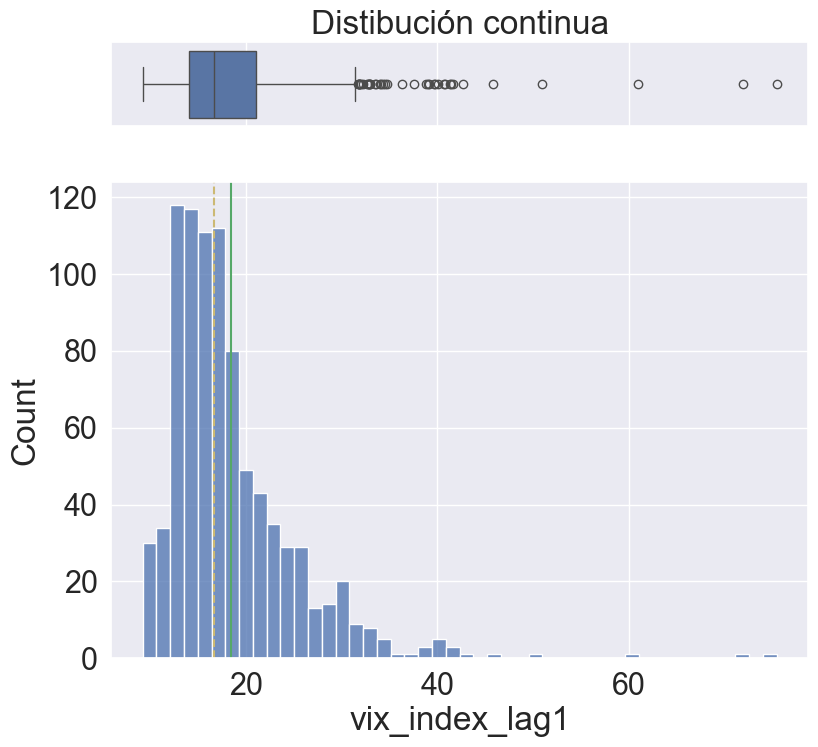

In [17]:
col = 'vix_index_lag1'
plot_col(df_merged[col])

## Transformations

In [18]:
log_cols = ['vix_index_lag1']
df_transformed = log_transform(df_merged, cols=log_cols, calculation_1p=False)

In [19]:
show_asymmetry(df_transformed)

vix_index_lag1_log              0.825430
treasury_10y_nominal_lag1       0.259717
oil_return                      0.112570
real_yield_10y_lag1             0.107836
target_gold_t1                 -0.106327
gold_return                    -0.107327
dxy_broad_goods_lag1           -0.515438
breakeven_inflation_10y_lag1   -0.669990
spy_return                     -1.059639


## Feature Engineering

In [20]:
# month of year
df_transformed = df_transformed.reset_index()
df_transformed['month_of_year'] = df_transformed['date'].dt.month
df_transformed.head()

,date,real_yield_10y_lag1,breakeven_inflation_10y_lag1,dxy_broad_goods_lag1,treasury_10y_nominal_lag1,gold_return,oil_return,spy_return,target_gold_t1,vix_index_lag1_log,month_of_year
0,2010-01-08,1.44,2.41,92.3684,3.85,0.008384,-0.039560,0.006480,-0.034920,2.947592,1
1,2010-01-15,1.40,2.36,91.5864,3.76,-0.034920,-0.041693,-0.028104,-0.017321,2.869602,1
2,2010-01-22,1.29,2.33,92.6627,3.62,-0.017321,-0.032072,-0.028021,-0.019564,3.103240,1
3,2010-01-29,1.35,2.33,93.2635,3.68,-0.019564,-0.006790,-0.019619,0.029932,3.166740,1
4,2010-02-05,1.27,2.35,94.1401,3.62,0.029932,0.029259,0.015877,0.021751,3.261169,2


In [21]:
df_transformed.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 875 entries, 0 to 874
Data columns (total 11 columns):
 #   Column                        Non-Null Count  Dtype         
---  ------                        --------------  -----         
 0   date                          875 non-null    datetime64[ns]
 1   real_yield_10y_lag1           875 non-null    float64       
 2   breakeven_inflation_10y_lag1  875 non-null    float64       
 3   dxy_broad_goods_lag1          875 non-null    float64       
 4   treasury_10y_nominal_lag1     875 non-null    float64       
 5   gold_return                   875 non-null    float64       
 6   oil_return                    875 non-null    float64       
 7   spy_return                    875 non-null    float64       
 8   target_gold_t1                874 non-null    float64       
 9   vix_index_lag1_log            875 non-null    float64       
 10  month_of_year                 875 non-null    int32         
dtypes: datetime64[ns](1), float64(9)

## Store clean data file

In [22]:
# Asegurar que los directorios existan
clean_data_file.parent.mkdir(parents=True, exist_ok=True)

# Guardar el dataframe
df_transformed.to_parquet(clean_data_file)
print("Clean data file saved.\n Continue to notebook 02_Modeling for the next phase.")


Clean data file saved.
 Continue to notebook 02_Modeling for the next phase.
